------------OUTPUT FUNGSI ANALISIS-----------

--------------Hasil input dari user-----------------
Vektor u                 :  [1 2]
Vektor v                 :  [-9 -8]
Skalar a                 :  2
Skalar b                 :  1

-------------------Hasil analisis-------------------
Hasil Penjumlahan u + v  : [-8 -6]
Hasil Pengurangan u - v  : [10 10]
Panjang Vektor u (|u|)   : 2.24
Panjang Vektor v (|v|)   : 12.04
Kombinasi Linear         : [-7 -4]
Nilai Rank               : 2
Nilai Independensi       : True

----------------INTERPRETASI HASIL--------------
#Independensi#
Ini merupakan vektor yang bebas linear (independen), karena kedua vektor memiliki informasi arah yang berbeda satu sama lain dan kedua vektor tersebut menunjuk ke arah yang berbeda.

#Rank (jumlah arah/dimensi)#
Kedua vektor mempunyai 2 arah yang berbeda.

#Span (rentangan)#
Bisa menjelajahi seluruh bidang 2D tanpa batas.

#Basis (syarat minimal yang dibutuhkan unutuk menjelajahi seluruh ruang#)
Kedua vektor tersebut

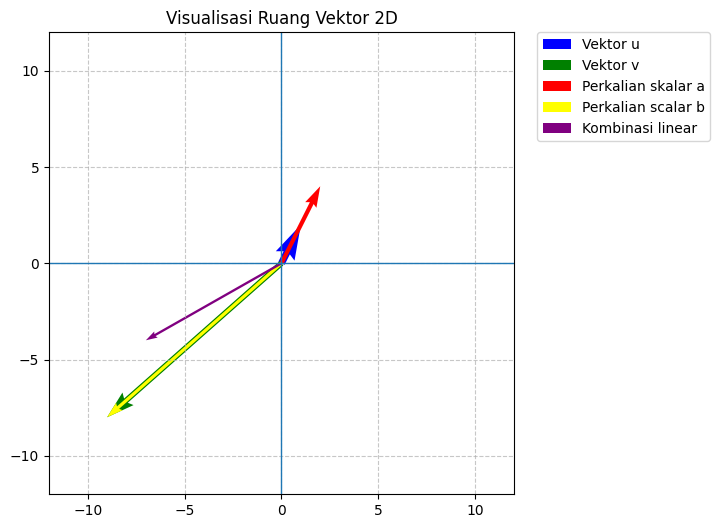

In [ ]:

# FUNGSI VISUALISASI
import numpy as np                                        #1
import matplotlib.pyplot as plt

#Deklarasikan form input untuk vektor u dan v
vektor_u = "1 2" #@param {type : "string"}
vektor_v = "-9 -8" #@param {type : "string"}

#Deklarasikan skalar a dan b untuk kombinasi linear
a = 2 #@param {type: "slider", min: -20, max: 20, step: 0.5}
b = 1 #@param {type: "slider", min: -20, max: 20, step: 0.5}


def analyze_vectors(u, v, a, b):
  try:
    u = np.array([int(x) for x in u.replace(',', ' ').split()])
    v = np.array([int(x) for x in v.replace(',', ' ').split()])

    if np.linalg.norm(u) == 0 or np.linalg.norm(v) == 0:
      raise ValueError("Vektor tidak boleh berupa titik nol (0,0) semua!")

    if u.shape != v.shape:
      raise ValueError("Dimensi u dan v harus sama")

 #Perhitungan analisis
    M = np.column_stack((u, v))
    rank = np.linalg.matrix_rank(M)

    return {
        "sum": u + v,
        "difference": u - v,
        "norm_u": np.linalg.norm(u),
        "norm_v": np.linalg.norm(v),
        "kombinasi" : (a*u) + (b*v),
        "rank": rank,
        "independent": int(rank) == 2,
        "basis_R2": len(u) == 2 and int(rank) == 2
    }

  except ValueError as e:
      print(f"Terjadi kesalahan input: {e}")
      return None

#Memanggil fungsi dan menyimpannya ke variabel 'hasil'
hasil = analyze_vectors(vektor_u, vektor_v, a, b)

u = np.array([int(x) for x in vektor_u.replace(',', ' ').split()])
v = np.array([int(x) for x in vektor_v.replace(',', ' ').split()])
kombinasi_linear = (a*u) + (b*v)

if hasil is not None:
  print ("------------OUTPUT FUNGSI ANALISIS-----------\n")

  print("--------------Hasil input dari user-----------------")
  print(f"Vektor u                 :  {u}")
  print(f"Vektor v                 :  {v}")
  print(f"Skalar a                 :  {a}")
  print(f"Skalar b                 :  {b}\n")

  print("-------------------Hasil analisis-------------------")
  print(f"Hasil Penjumlahan u + v  : {hasil['sum']}")
  print(f"Hasil Pengurangan u - v  : {hasil['difference']}")
  print(f"Panjang Vektor u (|u|)   : {hasil['norm_u']:.2f}")
  print(f"Panjang Vektor v (|v|)   : {hasil['norm_v']:.2f}")
  print(f"Kombinasi Linear         : {hasil['kombinasi']}")
  print(f"Nilai Rank               : {hasil['rank']}")
  print(f"Nilai Independensi       : {hasil['independent']}\n")


  print ("----------------INTERPRETASI HASIL--------------") #13
  #Independensi
  print ("#Independensi#")
  if hasil["rank"] == 2:
    print ("Ini merupakan vektor yang bebas linear (independen), karena kedua vektor memiliki informasi arah yang berbeda satu sama lain dan kedua vektor tersebut menunjuk ke arah yang berbeda.\n")
  else:
    print ("Ini merupakan vektor yang terikat linear (dependen), karena kedua vektor memiliki informasi arah yang sama yaitu vektor kedua merupakan kelipatan dari vektor pertama, kedua vektor tersebut menunjuk ke arah yang sama.\n")

  #Rank
  print ("#Rank (jumlah arah/dimensi)#")
  if hasil["rank"] == 2:
    print ("Kedua vektor mempunyai 2 arah yang berbeda.\n")
  else:
    print ("Kedua vektor hanya mempunyai 1 arah saja.\n")

  #Span
  print ("#Span (rentangan)#")
  if hasil["rank"] == 2:
    print ("Bisa menjelajahi seluruh bidang 2D tanpa batas.\n")
  else:
    print ("Hanya bisa menjelajahi 1 garis lurus saja, bergerak maju atau mundur.\n")

  #Basis
  print ("#Basis (syarat minimal yang dibutuhkan unutuk menjelajahi seluruh ruang#)")
  if hasil["rank"] == 2:
    print ("Kedua vektor tersebut bisa membentuk basis R² karena arahnya cukup untuk membuat bidang 2D.\n")
  else:
    print ("Kedua vektor tersebut tidak bisa membentuk basis R² karena arahnya tidak cukup untuk membuat bidang 2D.\n")



if hasil is not None:
  #FUNGSI VISUALISASI                                                           #14
  fig, ax = plt.subplots(figsize=(6,6))
  ax.axhline(0, linewidth=1)
  ax.axvline(0, linewidth=1)
                                                                                #15
  ax.quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color='blue', width=0.015, label='Vektor u')
  ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='green', width=0.012, label='Vektor v')
  ax.quiver(0, 0, a*u[0], a*u[1], angles='xy', scale_units='xy', scale=1, color='red', width=0.009, label='Perkalian skalar a')
  ax.quiver(0, 0, b*v[0], b*v[1], angles='xy', scale_units='xy', scale=1, color='yellow', width=0.007, label='Perkalian scalar b')
  ax.quiver(0, 0, kombinasi_linear[0], kombinasi_linear[1], angles='xy', scale_units='xy', scale=1, color='purple', width=0.005, label='Kombinasi linear')

                                                                                #16
  nilai_maksimum = max(abs(u[0]), abs(u[1]), abs(v[0]), abs(v[1]), abs(a*u[0]), abs(a*u[1]), abs(b*v[0]), abs(b*v[1]), abs(kombinasi_linear[0]), abs(kombinasi_linear[1])) + 3
  ax.set_xlim([-nilai_maksimum, nilai_maksimum])
  ax.set_ylim([-nilai_maksimum, nilai_maksimum])

                                                                                #17
  ax.grid(True, linestyle='--', alpha=0.7)
  ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

  ax.set_title("Visualisasi Ruang Vektor 2D")
  plt.show()

# **PENJELASAN FUNGSI ANALIS**
**1. Memasukkan library yang akan digunakan**

`import numpy as np`
* Masukkan pustaka yang berisi rumus komputasi numerik

`import matplotlib.pyplot as plt `
* Memasukkan pustaka untuk membuat visualisasi data dalam bentuk grafik atau plot 2D

**2. `def analyze_vectors(u, a, v, b): `**

* fungsi ini akan menerima variabel u,a,v,b
* Memasukkan fungsi def(define) = untuk mengambil rumusjari komputer atau cara kerja baru
* analyze_vektor(ini adalah nama fungsinya, boleh diganti) = memberi komputer untuk menghitung vektor yang nanti akan dimasukkan user menggunakan rumus yang akan kita tuliskan setelah ini
* semua yang rumus yatau perintah yang ada didalam def harus dijorokkan kedalam, biar komputer tau itu semua bagian dari def
def analyze_vectors(u, v):

**3. Validasi input untuk mencegah error**

```
 if np.linalg.norm(u) == 0 or np.linalg.norm(v) == 0:
    raise ValueError("Vektor tidak boleh berupa titik nol (0,0) semua!")
```
* Mengecek apakah vektor mengandung nilai 0 di kedua titiknya
* raise = rem/fungsi yang memerintahkan program untuk berhenti saat itu  juga
* ValueError = raise gak bisa berdiri sendiri, harus disertai jenis errornya, nah disini, jenis error nya adalah kesalahan "value" artinya nilainya salah secara logika

**4. `M = np.column_stack((u, v))`**

* Fungsi untuk menggabungkan vektor dan v ke dalam sebuah baris dan kolom menjadi matriks

**5. `rank = np.linalg.matrix_rank(M)`**

* Fungsi unutuk menentukan rank sebuah matriks. Rank adalah : jumlah maksimum baris atau kolom dalam matriks yang tidak bisa dibentuk dari kombinasi baris atau kolom lainnya (saling bebas linier atau independen). Nanti hasil perhitungannya  berupa satu angka bulat disimpan ke dalam variabel yang namanya rank
* matrix_rank (M) adalah fungsi khusus yang bertugas menghitung jumlah baris atau kolom yang saling bebas linear/independen dalam sebuah matriks

**6. `return {`**

* return = mengembalikan hasil dari satu nilai(value) saja ke dalam label/kuncinya (key). Tapi karena perhitungan ada banyak, kita pakai {}, nah jadi yang ada didalam kurung kurawal ini namanya dictionary.

**7. `("key/nilai" : value/isi)`**

(key/nilai) = kotak yang isinya ada perhitungan matematika (value/isi), nah nanti hasil dari perhitungan matematika dari value dikembalikan (return) ke kotaknya (key/nilai)

inilah stuktur dictionary-nya

*  ("sum": u + v,): Menghitung hasil penjumlahan vektor u + v
* ("difference": u - v,): Menghitung hasil pengurangan vektor u - v
*  ("norm_u": np.linalg.norm(u),): Menghitung norm (panjang/magnitudo) dari vektor
*  ("norm_v": np.linalg.norm(v),): Menghitung norm (panjang/magnitudo) dari vektor
*  ("rank": rank,): Menyimpan nilai rank matriks yang diperoleh dari Baris
* ("independent": rank == 2,): Memeriksa status bebas linear: menghasilkan nilai True jika rank sama dengan 2 (vektor saling independen), atau False jika dependen
* ("dependent": rank == 1,): Memeriksa status terikat linear: menghasilkan nilai True jika rank sama dengan 1 (vektor saling dependen), atau False jika independen
* ("tanpaarah": rank == 0,): Memeriksa apakah ranknya 0? jika iya maka akan menghasilkan nilai True
* "basis_R2": len(u) == 2 and rank == 2): Memeriksa syarat basis R² menghasilkan True jika vektor berdimensi 2 dan bernilai independen (rank = 2)

**8. `}`**
* menutup struktur dictionary

**9. `nama_variabel = nilaiawal #@param {type : "number"}`**

**`u_x = None`**
* Deklarasikan dulu variabel apa aja yang nanti akan di input user
* None artinya kotak kosong yang siap diisi user
* Btw None itu boleh kita isi angka, angka yang ada didalam sini sebagai contoh untuk user

**`#@param`**
*  (#@param) itu adalah fungsi atau sintaks untuk mengubah variabel kode menjadi kotak yang bisa diisi

**`{type : "number"}`**

**`{type : "slider", min: -5, max: 5, step: 0.5}`**
* konfigurasi tipe data, tipe data yang di inputkan user nanti adalah number, kotak kosong yang siap diisi number oleh user
* konfigurasi tipe data untuk skalar a dan b adalah "slider" berupa inputan angka dengan cara menggeser ke kiri (min/nilai turun) atau ke kanan (max/nilai bertambah)

**10.**
```
u = np.array([x, y])
v = np.array([x, y])
```
* gabungkan inputan user tadi kedalam bentuk numpy array
* di sini u_x jadi elemen indeks [0], dan u_y jadi elemen indeks [1]
* di sini v_x jadi elemen indeks [0], dan v_y jadi elemen indeks [1]

**11. `hasil = analyze_vectors(u, v, a, b)`**

* kotak penyimpanan seluruh perhitungan tadi (isi kotak hasil adalah isi perhitungan fungsi def yang bernama analyze_vector tadi)

**12.Output fungsi analisis**

`print(f"Tulisan yang mau ditampilakan : {{nama_kotak_berisi_hitungan['nama_key/nilai']}}")`

contoh `print(f"Hasil Penjumlahan u + v : {hasil['sum']}")`
* huruf f yang ada sebelum tanda kutip itu namanya f-string (formatted string literal). Cara Kerjanya: Ketika Python melihat huruf f di depan teks, Python tahu bahwa area di dalam kurung kurawal { } bukan teks biasa, melainkan kode Python (seperti nama variabel atau dictionary) yang nilainya harus dihitung dan ditampilkan.

**13.Interpretasi hasil**

#**PENJELASAN FUNGSI VISUALISASI**

**14.Menggambar grafik**

`fig, ax = plt.subplots(figsize=(6,6))`
* fig(figure/bingkai) dan ax(axis) adalah area untuk menggabar grafiknya
* fungsinya untuk menyiapkan tempat kosong baru yang bersih setiap kali kita mau menjalankan program atau menggeser slide skalar, figsize=(6,6) untuk mengatur ukuran tempat menggambar grafiknya
```
ax.axhline(0, linewidth=1)
ax.axvline(0, linewidth=1)
```
* fungsinya untuk menggambar garis horizontal dan vertikal dengan ketebalan garis = 1 (semakin besar angkanya maka semakin tebal)

**15. Menggambar garis vektor**
```
ax.quiver(0, 0, u[0], u[1], angles='xy', scale_units='xy', scale=1, color='blue', alpha=0.8, label='Vektor u')
```
* fungsinya untuk menggambar garis vektor mulai dari titik 0 ke titik u, dengan pengaturan :  
- angles (mengatur arah dan sudut panah agar mengikuti koordinat sumbu x dan y),
- scale_units (menyamakan satuan ukuran panjang panah dengan skala yang ada di sumbu x dan y),
- scale=1 (menentukan faktor skala ukuran panah agar panah yang di tampilkan apa adanya sesuai nilai koordinat),
- color (mengatur warna garis panah),
- alpha (mengatur tingkat transparansi/tembus pandang vektornya),
- label (memberikan nama keterangan atau teks label unutk panah tersebut).

**16. Menghitung batas vektor yang paling panjang secara otomatis agar gambar garis vektor tidak terpotong**

`nilai_maksimum = max(abs(u[0]), abs(u[1]), abs(v[0]), abs(v[1]), abs(a*u[0]), abs(a*u[1]), abs(b*v[0]), abs(b*v[1]), abs(kombinasi_linear[0]), abs(kombinasi_linear[1])) + 3`
* abs() artinya komputer sedang mencari angka yang paling besar diantara komponen yang ada di dalamnya (u,v,a,b dst..), nanti setelah komputer tau diantara komponen itu mana yang paling besar, angkanya ditambah 3 sebagai ruang kosong yang disediakan di pinggir grafik.
```
ax.set_xlim([-max_val, max_val])
ax.set_ylim([-max_val, max_val])
```
* setelah komputer tau mana kompoter yang angkanya paling besar, dan menambahkannya dengan angka 3, hasilnya (nilai_maksimum) tadi dipakai untuk mengatur rentang garis sumbu horizontal (x) dari minus ke positif (-nilai_maksimum) sampai (nilai_maksimum) dan sumbu vertikal (y). Karena angka negatif dan positifnya sama besar, hasil kotaknya akan berbentuk persegi empat, jadi sudut antar vektornya tidak akan melar.

**17.Penyempurnaan agar grafik siap ditampilkan**

`ax.grid(True, linestyle='--', alpha=0.7)`
* ax.grid (menampilakna kotak kotak pada grafik),
* linestyle (gaya garis garisnya nanti adalah '--' garis putus-putus),
* alpha (transparasi garis garisnya  nanti adalah tipis (0.7)

`ax.legend()`
* untuk menampilkan kotak keterangan vektornya

`ax.set_title("Visualisasi Ruang Vektor 2D")`
* unutk atur judul grafik

`plt.show()`
* untuk menampilkan grafiknya

**Kenapa pakai awalan ax.?**
* karena dari awal udah pakai (fig, ax)
Dengan memakai fig, ax, setiap kali slider digeser, komputer tahu persis bahwa kanvas ax yang lama harus ditimpa atau dibersihkan dulu sebelum menggambar vektor yang baru, sehingga grafiknya selalu bersih dan mulus.

* kita ingin menempelkan atau memasukkan semua elemen gambar tersebut secara spesifik ke dalam satu kanvas (ax) yang sama yang sudah kita buat di awal lewat fig, ax = plt.subplots(...).

* Jika kita pakai plt., perintahnya bersifat global (menempel ke modul utama, bukan ke kanvas spesifik kita). Jadi kesimpulannya: ax adalah nama wadah/kanvas spesifik kita, bukan khusus untuk vektor.

















